# F1 Moodle Activity: Predicting Students at Risk

## Modeling

This notebook develops models for identifying students who are at risk of failing the course based on Moodle activity and early homework performance.

The features are prepared using the project data preparation pipeline. All features use information available before the cutoff, which is defined as one week before the first midterm.

The models are trained on students from 2019 and 2021–2024 and tested on students from 2025–2026.

In [1]:
import sys
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, roc_auc_score

sys.path.append("../src")
from prepare import build_features

## 1. Data preparation

The final feature table is created by `build_features()` from the project data.

One row represents one student in one academic year.

The target variable is `fail`:

- 1 = F grade or no grade
- 0 = A–E grade

The table contains activity features and early homework features calculated using only information available before the cutoff.

In [2]:
import sys

sys.path.append("../src")

from prepare import build_features

data = build_features("../data")

print(data.shape)
print(data.columns.tolist())
display(data.head())

(843, 17)
['year', 'actor_id', 'fail', 'is_repeat', 'active_days', 'active_weeks', 'first_day_lag', 'active_weeks_share', 'active_days_last_2_weeks', 'days_forum', 'days_grades', 'days_homework', 'days_lectures', 'days_materials', 'hw_early_count', 'hw_early_submitted_share', 'hw_early_mean']


,year,actor_id,fail,is_repeat,active_days,active_weeks,first_day_lag,active_weeks_share,active_days_last_2_weeks,days_forum,days_grades,days_homework,days_lectures,days_materials,hw_early_count,hw_early_submitted_share,hw_early_mean
0,2019,S027cf9,0,0,18,6,19,0.666667,5,0,1,18,0,4,5,1.0,83.8
1,2019,S032255,0,0,6,5,21,0.555556,2,1,0,6,0,2,5,0.4,4.4
2,2019,S03a8b8,0,0,30,8,0,0.888889,9,1,16,22,0,10,5,1.0,106.4
3,2019,S04cf7f,0,0,21,9,6,1.000000,7,0,5,18,0,3,5,1.0,94.4
4,2019,S05f285,1,0,32,7,7,0.777778,13,2,25,25,0,12,5,1.0,86.2


### Train and test split

To evaluate whether the model generalizes to newer academic years, the data is split by year instead of randomly.

- Training data: 2019 and 2021–2024
- Test data: 2025–2026
- 2020 is excluded because the prepared dataset does not contain a valid target for that year.

In [3]:
train = data[
    data["year"].isin([2019, 2021, 2022, 2023, 2024])
].copy()

test = data[
    data["year"].isin([2025, 2026])
].copy()

print("Train:", train.shape)
print("Test:", test.shape)

print("\nTrain years:")
print(train["year"].value_counts().sort_index())

print("\nTest years:")
print(test["year"].value_counts().sort_index())

Train: (564, 17)
Test: (279, 17)

Train years:
year
2019    114
2021    142
2022     83
2023    106
2024    119
Name: count, dtype: int64

Test years:
year
2025    137
2026    142
Name: count, dtype: int64


In [4]:
print("Train target distribution:")
print(train["fail"].value_counts())

print("\nTest target distribution:")
print(test["fail"].value_counts())

Train target distribution:
fail
0    482
1     82
Name: count, dtype: int64

Test target distribution:
fail
0    234
1     45
Name: count, dtype: int64


## 2. Baseline

As a simple baseline, we use only `active_days`.

A student is classified as being at risk if they were active on 15 or fewer days before the cutoff.

This is a simple reference rule and does not use the other available features.

In [5]:
baseline_threshold = 15

y_train = train["fail"].astype(int)
y_test = test["fail"].astype(int)

y_train_baseline = (
    train["active_days"] <= baseline_threshold
).astype(int)

y_test_baseline = (
    test["active_days"] <= baseline_threshold
).astype(int)

baseline_train_recall = recall_score(
    y_train,
    y_train_baseline,
    zero_division=0
)

baseline_train_precision = precision_score(
    y_train,
    y_train_baseline,
    zero_division=0
)

baseline_test_recall = recall_score(
    y_test,
    y_test_baseline,
    zero_division=0
)

baseline_test_precision = precision_score(
    y_test,
    y_test_baseline,
    zero_division=0
)

print("Baseline threshold:", baseline_threshold)

print("\nTrain recall:", baseline_train_recall)
print("Train precision:", baseline_train_precision)

print("\nTest recall:", baseline_test_recall)
print("Test precision:", baseline_test_precision)

Baseline threshold: 15

Train recall: 0.6219512195121951
Train precision: 0.3617021276595745

Test recall: 0.7333333333333333
Test precision: 0.358695652173913


### Baseline result

The baseline provides a simple reference for the machine learning models.

Its performance on the 2025–2026 test data will be compared with Logistic Regression and Random Forest.

In [6]:
features = [
    "is_repeat",
    "active_days",
    "active_weeks",
    "active_weeks_share",
    "first_day_lag",
    "active_days_last_2_weeks",
    "days_materials",
    "days_homework",
    "days_lectures",
    "days_forum",
    "days_grades",
    "hw_early_count",
    "hw_early_submitted_share",
    "hw_early_mean"
]

X_train = train[features].copy()
X_test = test[features].copy()

y_train = train["fail"].astype(int)
y_test = test["fail"].astype(int)

X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

print("Number of features:", len(features))
print("Features:")
print(features)

print("\nTrain shape:", X_train.shape)
print("Test shape:", X_test.shape)

Number of features: 14
Features:
['is_repeat', 'active_days', 'active_weeks', 'active_weeks_share', 'first_day_lag', 'active_days_last_2_weeks', 'days_materials', 'days_homework', 'days_lectures', 'days_forum', 'days_grades', 'hw_early_count', 'hw_early_submitted_share', 'hw_early_mean']

Train shape: (564, 14)
Test shape: (279, 14)


## 3. Cross-validation and threshold selection

The classification threshold should not be selected using the same training predictions that were produced by a model trained on all training observations.

To avoid this problem, we use 5-fold stratified cross-validation and obtain out-of-fold (OOF) probabilities. The threshold is then selected using only these OOF predictions.

The project criteria are:

- recall ≥ 0.70
- precision ≥ 1/3

The 2025–2026 test data is not used when selecting the threshold.

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression
logistic_cv_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_oof_prob = cross_val_predict(
    logistic_cv_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]


# Random Forest
rf_cv_model = RandomForestClassifier(
    n_estimators=100,
    random_state=1
)

rf_oof_prob = cross_val_predict(
    rf_cv_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]


print("Cross-validation predictions created.")
print("Logistic Regression OOF probabilities:", len(logistic_oof_prob))
print("Random Forest OOF probabilities:", len(rf_oof_prob))

Cross-validation predictions created.
Logistic Regression OOF probabilities: 564
Random Forest OOF probabilities: 564


In [19]:
def find_cv_threshold(y_true, probabilities):
    results = []

    for threshold in np.arange(0.05, 0.96, 0.01):

        y_pred = (
            probabilities >= threshold
        ).astype(int)

        recall = recall_score(
            y_true,
            y_pred,
            zero_division=0
        )

        precision = precision_score(
            y_true,
            y_pred,
            zero_division=0
        )

        results.append({
            "threshold": threshold,
            "recall": recall,
            "precision": precision
        })

    results = pd.DataFrame(results)

    # Thresholds satisfying both project criteria
    valid = results[
        (results["recall"] >= 0.70) &
        (results["precision"] >= 1/3)
    ]

    if len(valid) > 0:
        best = valid.sort_values(
            ["recall", "precision"],
            ascending=[False, False]
        ).iloc[0]

    else:
        # If both criteria cannot be satisfied,
        # maximize recall among thresholds with precision >= 1/3
        valid_precision = results[
            results["precision"] >= 1/3
        ]

        best = valid_precision.sort_values(
            ["recall", "precision"],
            ascending=[False, False]
        ).iloc[0]

    return best, results


logistic_cv_best, logistic_cv_thresholds = find_cv_threshold(
    y_train,
    logistic_oof_prob
)

rf_cv_best, rf_cv_thresholds = find_cv_threshold(
    y_train,
    rf_oof_prob
)

print("Logistic Regression CV threshold:")
print(logistic_cv_best)

print("\nRandom Forest CV threshold:")
print(rf_cv_best)

Logistic Regression CV threshold:
threshold    0.110000
recall       0.768293
precision    0.364162
Name: 6, dtype: float64

Random Forest CV threshold:
threshold    0.110000
recall       0.817073
precision    0.343590
Name: 6, dtype: float64


## 4. Logistic Regression

We train a Logistic Regression model using all 14 available features.

The model produces a probability of failure for each student.

Model performance is evaluated using AUC on the 2025–2026 test data. The classification threshold is selected separately using cross-validation on the training data.

In [38]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(
    X_train,
    y_train
)

train_prob_logistic = logistic_model.predict_proba(
    X_train
)[:, 1]

test_prob_logistic = logistic_model.predict_proba(
    X_test
)[:, 1]

print("First 10 Logistic Regression probabilities:")
print(test_prob_logistic[:10])

First 10 Logistic Regression probabilities:
[0.02456458 0.0226633  0.00700081 0.11882149 0.75027398 0.02638228
 0.0327806  0.57501129 0.03831368 0.15662238]


In [39]:
logistic_train_auc = roc_auc_score(
    y_train,
    train_prob_logistic
)

logistic_test_auc = roc_auc_score(
    y_test,
    test_prob_logistic
)

print("Logistic Regression Train AUC:", logistic_train_auc)
print("Logistic Regression Test AUC:", logistic_test_auc)

Logistic Regression Train AUC: 0.9000860236818135
Logistic Regression Test AUC: 0.8286799620132954


### Logistic Regression AUC

The Logistic Regression model achieved a test AUC of approximately 0.829.

AUC measures how well the model separates students who eventually fail from students who do not fail, independently of a particular classification threshold.

### Cross-validation threshold selection

The classification threshold was selected using out-of-fold predictions from 5-fold stratified cross-validation.

For Logistic Regression, the selected threshold is 0.11. On the cross-validation predictions, this threshold achieved recall of approximately 0.768 and precision of approximately 0.364.

The threshold was selected without using the 2025–2026 test data.

In [33]:
logistic_threshold_cv = logistic_cv_best["threshold"]

logistic_test_pred_cv = (
    test_prob_logistic >= logistic_threshold_cv
).astype(int)

logistic_test_recall_cv = recall_score(
    y_test,
    logistic_test_pred_cv,
    zero_division=0
)

logistic_test_precision_cv = precision_score(
    y_test,
    logistic_test_pred_cv,
    zero_division=0
)

print("Logistic Regression")
print("CV-selected threshold:", logistic_threshold_cv)
print("Test recall:", logistic_test_recall_cv)
print("Test precision:", logistic_test_precision_cv)

Logistic Regression
CV-selected threshold: 0.11000000000000001
Test recall: 0.6222222222222222
Test precision: 0.4827586206896552


### Logistic Regression result

Using the threshold selected through cross-validation, Logistic Regression achieved a test recall of approximately 0.622 and a test precision of approximately 0.483.

The precision requirement of 1/3 is satisfied, but the target recall of 0.70 is not reached on the 2025–2026 test data.

## 5. Random Forest

We train a Random Forest using the same 14 features as the Logistic Regression model.

This allows us to compare the two machine learning approaches using the same information.

In [12]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=1
)

rf_model.fit(
    X_train,
    y_train
)

train_prob_rf = rf_model.predict_proba(
    X_train
)[:, 1]

test_prob_rf = rf_model.predict_proba(
    X_test
)[:, 1]

print("First 10 Random Forest probabilities:")
print(test_prob_rf[:10])

First 10 Random Forest probabilities:
[0.   0.   0.02 0.08 0.87 0.25 0.   0.64 0.13 0.21]


In [13]:
rf_train_auc = roc_auc_score(
    y_train,
    train_prob_rf
)

rf_test_auc = roc_auc_score(
    y_test,
    test_prob_rf
)

print("Random Forest Train AUC:", rf_train_auc)
print("Random Forest Test AUC:", rf_test_auc)

Random Forest Train AUC: 1.0
Random Forest Test AUC: 0.795868945868946


### Random Forest AUC

The Random Forest achieved a test AUC of approximately 0.796.

The model is evaluated using the same training and test split as Logistic Regression.

### Cross-validation threshold selection

The Random Forest classification threshold was selected using out-of-fold predictions from 5-fold stratified cross-validation.

The selected threshold is 0.11. On the cross-validation predictions, this threshold achieved recall of approximately 0.817 and precision of approximately 0.344.

The 2025–2026 test data was not used when selecting the threshold.

In [40]:
rf_threshold_cv = rf_cv_best["threshold"]

rf_test_pred_cv = (
    test_prob_rf >= rf_threshold_cv
).astype(int)

rf_test_recall_cv = recall_score(
    y_test,
    rf_test_pred_cv,
    zero_division=0
)

rf_test_precision_cv = precision_score(
    y_test,
    rf_test_pred_cv,
    zero_division=0
)

print("Random Forest")
print("CV-selected threshold:", rf_threshold_cv)
print("Test recall:", rf_test_recall_cv)
print("Test precision:", rf_test_precision_cv)

Random Forest
CV-selected threshold: 0.11000000000000001
Test recall: 0.6666666666666666
Test precision: 0.32608695652173914


### Random Forest result

Using the threshold selected through cross-validation, Random Forest achieved a test recall of approximately 0.667 and a test precision of approximately 0.327.

The model is close to the target recall of 0.70, but does not reach it. Its precision is slightly below the required 1/3.

### Feature importance

Feature importance shows which predictors contribute most to the Random Forest model.

The analysis is based on the Random Forest using all 14 features, including early homework information.

In [41]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

display(feature_importance)

,feature,importance
13,hw_early_mean,0.184178
12,hw_early_submitted_share,0.119409
7,days_homework,0.109986
5,active_days_last_2_weeks,0.086243
1,active_days,0.085945
3,active_weeks_share,0.068190
4,first_day_lag,0.061985
10,days_grades,0.058196
6,days_materials,0.053471
2,active_weeks,0.050895


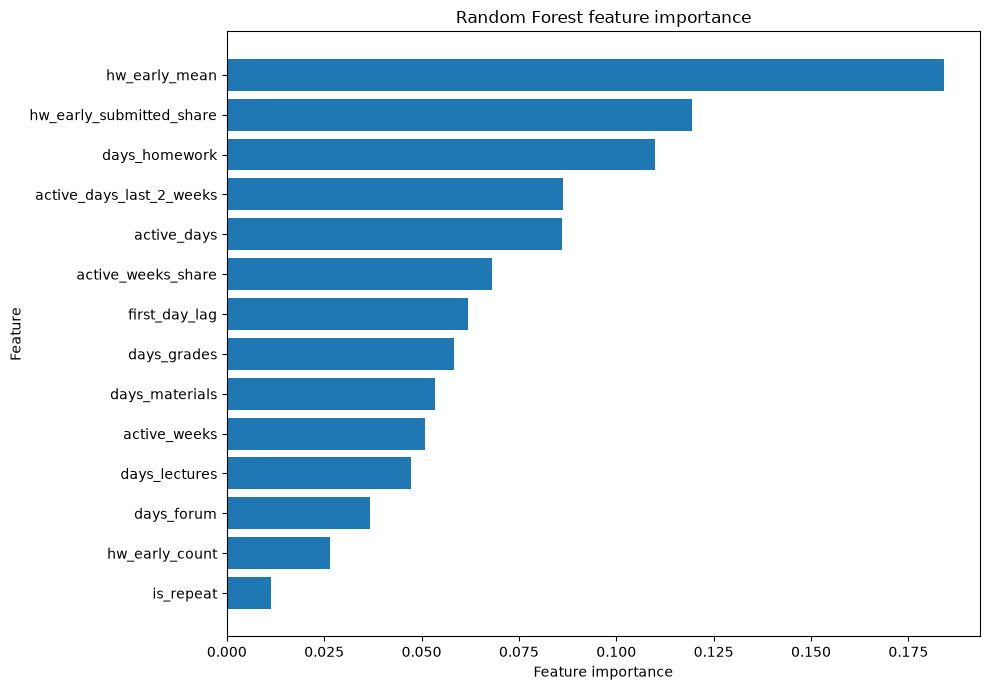

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Random Forest feature importance")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Figure 3. Random Forest feature importance

The most important feature is `hw_early_mean`, followed by `hw_early_submitted_share` and `days_homework`. This indicates that early homework performance and homework-related activity are important predictors of course failure.

General Moodle activity features such as `active_days_last_2_weeks` and `active_days` are also among the more important predictors. In contrast, `is_repeat` has relatively low importance in the model.

## 6. Activity-only vs Activity + homework

To evaluate whether early homework information improves prediction, we compare two feature sets.

The first model uses only general Moodle activity features.

The second model uses the same activity features plus three early homework features:

- `hw_early_count`
- `hw_early_submitted_share`
- `hw_early_mean`

Both models use the same train/test split and the same cross-validation procedure.

In [43]:
activity_features = [
    "is_repeat",
    "active_days",
    "active_weeks",
    "active_weeks_share",
    "first_day_lag",
    "active_days_last_2_weeks",
    "days_materials",
    "days_homework",
    "days_lectures",
    "days_forum",
    "days_grades"
]

X_train_activity = train[activity_features].copy()
X_test_activity = test[activity_features].copy()

X_train_activity = X_train_activity.fillna(0)
X_test_activity = X_test_activity.fillna(0)

print("Activity-only features:", activity_features)
print("Train shape:", X_train_activity.shape)
print("Test shape:", X_test_activity.shape)

Activity-only features: ['is_repeat', 'active_days', 'active_weeks', 'active_weeks_share', 'first_day_lag', 'active_days_last_2_weeks', 'days_materials', 'days_homework', 'days_lectures', 'days_forum', 'days_grades']
Train shape: (564, 11)
Test shape: (279, 11)


In [44]:
activity_logistic_cv_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

activity_logistic_oof_prob = cross_val_predict(
    activity_logistic_cv_model,
    X_train_activity,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]


activity_rf_cv_model = RandomForestClassifier(
    n_estimators=100,
    random_state=1
)

activity_rf_oof_prob = cross_val_predict(
    activity_rf_cv_model,
    X_train_activity,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]


print("Activity-only cross-validation predictions created.")
print(
    "Logistic Regression OOF probabilities:",
    len(activity_logistic_oof_prob)
)
print(
    "Random Forest OOF probabilities:",
    len(activity_rf_oof_prob)
)

Activity-only cross-validation predictions created.
Logistic Regression OOF probabilities: 564
Random Forest OOF probabilities: 564


In [45]:
activity_logistic_cv_best, activity_logistic_cv_thresholds = find_cv_threshold(
    y_train,
    activity_logistic_oof_prob
)

activity_rf_cv_best, activity_rf_cv_thresholds = find_cv_threshold(
    y_train,
    activity_rf_oof_prob
)

print("Activity-only Logistic Regression CV threshold:")
print(activity_logistic_cv_best)

print("\nActivity-only Random Forest CV threshold:")
print(activity_rf_cv_best)

Activity-only Logistic Regression CV threshold:
threshold    0.140000
recall       0.756098
precision    0.354286
Name: 9, dtype: float64

Activity-only Random Forest CV threshold:
threshold    0.160000
recall       0.719512
precision    0.355422
Name: 11, dtype: float64


In [46]:
activity_logistic_final = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

activity_logistic_final.fit(
    X_train_activity,
    y_train
)

activity_logistic_test_prob = activity_logistic_final.predict_proba(
    X_test_activity
)[:, 1]


activity_rf_final = RandomForestClassifier(
    n_estimators=100,
    random_state=1
)

activity_rf_final.fit(
    X_train_activity,
    y_train
)

activity_rf_test_prob = activity_rf_final.predict_proba(
    X_test_activity
)[:, 1]


print("Activity-only final models trained.")

Activity-only final models trained.


In [47]:
activity_logistic_threshold = activity_logistic_cv_best["threshold"]
activity_rf_threshold = activity_rf_cv_best["threshold"]


# Activity-only Logistic Regression
activity_logistic_test_pred = (
    activity_logistic_test_prob >= activity_logistic_threshold
).astype(int)

activity_logistic_test_recall = recall_score(
    y_test,
    activity_logistic_test_pred,
    zero_division=0
)

activity_logistic_test_precision = precision_score(
    y_test,
    activity_logistic_test_pred,
    zero_division=0
)


# Activity-only Random Forest
activity_rf_test_pred = (
    activity_rf_test_prob >= activity_rf_threshold
).astype(int)

activity_rf_test_recall = recall_score(
    y_test,
    activity_rf_test_pred,
    zero_division=0
)

activity_rf_test_precision = precision_score(
    y_test,
    activity_rf_test_pred,
    zero_division=0
)


print("Activity-only Logistic Regression")
print("CV-selected threshold:", activity_logistic_threshold)
print("Test recall:", activity_logistic_test_recall)
print("Test precision:", activity_logistic_test_precision)

print("\nActivity-only Random Forest")
print("CV-selected threshold:", activity_rf_threshold)
print("Test recall:", activity_rf_test_recall)
print("Test precision:", activity_rf_test_precision)

Activity-only Logistic Regression
CV-selected threshold: 0.14
Test recall: 0.6666666666666666
Test precision: 0.2830188679245283

Activity-only Random Forest
CV-selected threshold: 0.16000000000000003
Test recall: 0.6222222222222222
Test precision: 0.24778761061946902


In [48]:
activity_logistic_test_auc = roc_auc_score(
    y_test,
    activity_logistic_test_prob
)

activity_rf_test_auc = roc_auc_score(
    y_test,
    activity_rf_test_prob
)

print(
    "Activity-only Logistic Regression Test AUC:",
    activity_logistic_test_auc
)

print(
    "Activity-only Random Forest Test AUC:",
    activity_rf_test_auc
)

Activity-only Logistic Regression Test AUC: 0.7441595441595441
Activity-only Random Forest Test AUC: 0.7296771130104464


## 7. Final model comparison

The following table compares four models on the 2025–2026 test data.

The comparison shows whether adding early homework information improves prediction compared with using Moodle activity alone.

In [49]:
final_model_comparison = pd.DataFrame({
    "model": [
        "Activity-only Logistic Regression",
        "Activity + homework Logistic Regression",
        "Activity-only Random Forest",
        "Activity + homework Random Forest"
    ],
    "test_auc": [
        activity_logistic_test_auc,
        logistic_test_auc,
        activity_rf_test_auc,
        rf_test_auc
    ],
    "test_recall": [
        activity_logistic_test_recall,
        logistic_test_recall_cv,
        activity_rf_test_recall,
        rf_test_recall_cv
    ],
    "test_precision": [
        activity_logistic_test_precision,
        logistic_test_precision_cv,
        activity_rf_test_precision,
        rf_test_precision_cv
    ]
})

display(final_model_comparison)

,model,test_auc,test_recall,test_precision
0,Activity-only Logistic Regression,0.744160,0.666667,0.283019
1,Activity + homework Logistic Regression,0.828680,0.622222,0.482759
2,Activity-only Random Forest,0.729677,0.622222,0.247788
3,Activity + homework Random Forest,0.795869,0.666667,0.326087


## Interpretation of results

Adding early homework information improved the discrimination ability of both machine learning models.

For Logistic Regression, test AUC increased from 0.744 with activity-only features to 0.829 when early homework features were added. Precision also increased from 0.283 to 0.483.

For Random Forest, test AUC increased from 0.730 to 0.796, while recall increased from 0.622 to 0.667.

However, none of the machine learning models reached the target recall of 0.70 on the 2025–2026 test data.

The results suggest that early homework information contains useful predictive information, but it does not guarantee better recall on newer cohorts.

## 8. Final results and discussion

The baseline achieved a test recall of 0.733 and a precision of 0.359.

Among the machine learning models, Logistic Regression with activity and early homework features achieved the highest test AUC of 0.829 and the highest precision of 0.483.

Random Forest with activity and early homework features achieved a test recall of 0.667, which was the highest recall among the machine learning models, but it did not reach the target recall of 0.70.

Therefore, the simple baseline remains the strongest approach for the main goal of identifying as many failing students as possible, while Logistic Regression provides the best overall ranking performance according to AUC.

The difference between cross-validation and test performance suggests that the models do not generalize perfectly from historical cohorts to the newer 2025–2026 cohorts. Changes in Moodle usage patterns, course organization, and student behaviour between academic years may contribute to this difference.

## 9. Limitations

There are several limitations to the prediction task.

First, Moodle usage patterns changed between academic years. Some tools were not available or were used differently in different years, so the same feature may not have exactly the same meaning across cohorts.

Second, the prediction cutoff is one week before the first midterm. Students may become much more active after this cutoff while preparing for the midterm. Such activity cannot be used by the model because the goal is to provide an early warning.

Third, the test data consists of newer cohorts from 2025–2026, while the models are trained on earlier cohorts. The lower test performance therefore suggests that changes between cohorts are important and should be considered when interpreting the results.

Finally, threshold selection is based on cross-validation within the historical training data. The selected threshold may still not transfer perfectly to future cohorts.